Домашнее задание по теме 4

$\textbf{Часть 1}$

а) укажите p-value критериев Смирнова, Андерсона ― Дарлинга и двустороннего критерия Манна — 
Уитни и сделайте вывод, отвергается ли на уровне значимости 0,05 гипотеза однородности выборок;

In [54]:
import numpy as np
from scipy import stats

X = np.random.normal(0, 1, size=50) 
Y = np.random.normal(0, 3, size=50)

res_Smirnov = stats.ks_2samp(X,Y)
print(res_Smirnov.pvalue)

0.005841778142694731


In [55]:
res_AD = stats.anderson_ksamp([X,Y])
print(res_AD.pvalue)

0.001


C:\Users\A\AppData\Local\Temp\ipykernel_23376\3080247614.py:1: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  res_AD = stats.anderson_ksamp([X,Y])
C:\Users\A\AppData\Local\Temp\ipykernel_23376\3080247614.py:1: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  res_AD = stats.anderson_ksamp([X,Y])


In [56]:
res_MW = stats.mannwhitneyu(X,Y,alternative='two-sided')
print(res_MW.pvalue)

0.7800915700498592


Критерии Смирнова и Андерсона-Дарлинга показали p-value < 0.05, поэтому мы можем отвергнуть гипотезу однородности на уровне 0.05.

б) постройте на одном рисунке с помощью кода на Python графики эмпирических функций 
распределения выборок; 

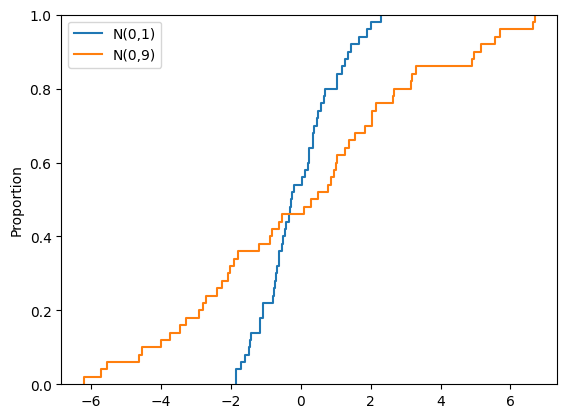

In [57]:
import matplotlib.pyplot as plt
import seaborn as sb

sb.ecdfplot(X, label='N(0,1)')
sb.ecdfplot(Y, label='N(0,9)')
plt.legend()
plt.show()

в) объясните, почему критерий Манна ― Уитни не обнаруживает различия распределений выборок.

Критерий Манна-Уитни ловит альтернативу доминирования, а в нашем случае доминирования не наблюдается. Половину графика доминирует одна ЭФР, во второй половине доминирует другая ЭФР.

$\textbf{Часть 2}$

$\textbf{Задача}$ Рассмотрим статистику критерия Манна-Уитни:
$$U=\sum\limits_{i=1}^{n}\sum\limits_{j=1}^{m}I\{X_i<Y_j\}.$$
Надо показать, что если $X_i$ и $Y_j$ одинаково распределены, то $DU=nm(n+m+1)/12$.

$\textbf{Доказательство:}$
$$ EU = \sum\limits_{i=1}^{n}\sum\limits_{j=1}^{m}P(X_i<Y_j)=\sum\limits_{i=1}^{n}\sum\limits_{j=1}^{m}1/2=nm/2.$$
$$ U^2 = \sum\limits_{i=1}^{n}\sum\limits_{j=1}^{m}\sum\limits_{k=1}^{n}\sum\limits_{l=1}^{m}I\{X_i<Y_j,X_k<Y_l\}.$$
Обозначим $p_{ijkl}:=P(X_i<Y_j,X_k<Y_l)$. Рассмотрим 4 случая:
1) $i\neq k, j \neq l$. Тогда $p_{ijkl}=1/2 \cdot 1/2 = 1/4$.
2) $i=k, j \neq l$. Тогда $p_{ijil}=1/3$.
3) $i\neq k, j = l$. Тогда $p_{ijij}=1/3$.
4) $i= k, j = l$. Тогда $p_{ijij}=1/2$.
Тогда имеем:
$$  EU^2 = \sum\limits_{i=1}^{n}\sum\limits_{j=1}^{m}\sum\limits_{k=1}^{n}\sum\limits_{l=1}^{m}p_{ijkl}=\frac{1}{4}(n^2m^2-nm-n(n-1)m-nm(m-1))+\frac{1}{3}(n(n-1)m+nm(m-1))+\frac{1}{2}nm=$$
$$=\frac{1}{4}n^2m^2+\frac{1}{12}nm(n+m+1).$$
$$DU=EU^2-(EU)^2=nm(n+m+1)/12.$$
$\Box$